# Kalibracja PD: diagnostyka, Platt vs izotoniczna i dostosowanie do tendencji centralnej 4%

----
## 0. Importy

In [1]:
import sys, json; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy.stats import spearmanr
from src import config as cfg
from src.data import load_data, load_splits
from src.models import load_predictions
from src.calibration import (calib_report, reliability, log_axes, FIT, apply_cal, cv_logloss, delta_to_mean, shift)
plt.style.use('default')

----
## 1. Predykcje

In [2]:
df = load_data(); splits = load_splits(); y = df[cfg.TARGET]
va, te = splits['valid'], splits['test']
MODELS = {'logit': 'logit', 'black-box': 'lgbm_mono'}
P = {}
for name, key in MODELS.items():
    pr = load_predictions(key).set_index('id')
    P[name] = {s: pr[pr.zbior == s].loc[ids, 'p'].to_numpy() for s, ids in [('valid', va), ('test', te)]}
Y = {'valid': y.loc[va].to_numpy(), 'test': y.loc[te].to_numpy()}
print(f"DR: valid {Y['valid'].mean():.2%}, test {Y['test'].mean():.2%} | cel PD = {cfg.PD_TARGET:.0%}")

DR: valid 13.75%, test 13.78% | cel PD = 4%


----
## 2. Diagnostyka przed kalibracją

,DR,średnie PD,AUC,Brier,log-loss,ECE,ACE,CITL (intercept),slope
logit,0.1375,0.1426,0.7481,0.1064,0.3542,0.0436,0.0395,-0.0481,0.9346
black-box,0.1375,0.1430,0.7585,0.1046,0.3482,0.0227,0.0328,-0.0513,1.1053


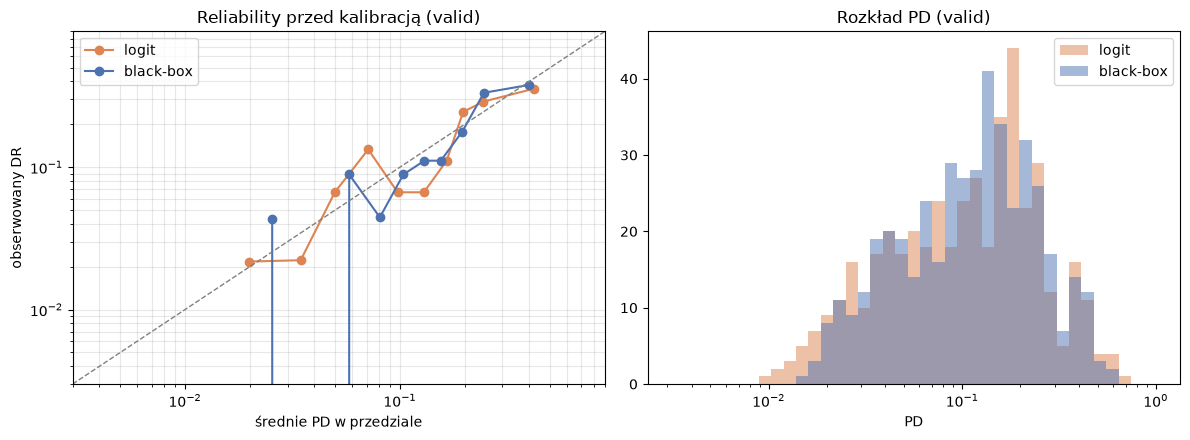

In [3]:
pre = pd.DataFrame({m: calib_report(Y['valid'], P[m]['valid']) for m in MODELS}).T
display(pre.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m, col in zip(MODELS, ['#DD8452', '#4C72B0']):
    reliability(axes[0], Y['valid'], P[m]['valid'], m, color=col)
    axes[1].hist(P[m]['valid'], bins=np.logspace(-2.5, 0, 40), alpha=0.5, label=m, color=col)
log_axes(axes[0]); axes[0].set_title('Reliability przed kalibracją (valid)'); axes[0].legend()
axes[1].set_xscale('log'); axes[1].set_xlabel('PD'); axes[1].set_title('Rozkład PD (valid)'); axes[1].legend()
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '06_pre_cal.png', dpi=150); plt.show()

**Wnioski:** przed kalibracją oba modele są blisko przekątnej.

----
## 3. Wybór metody kalibracji

In [4]:
choice = pd.DataFrame({m: {met: cv_logloss(met, Y['valid'], P[m]['valid']) for met in FIT} for m in MODELS}).T
choice['wybrana metoda'] = choice[['Platt', 'izotoniczna']].idxmin(axis=1)
choice.to_csv(cfg.TAB_DIR / '06_wybor_metody.csv')
choice.round(5)

,bez kalibracji,Platt,izotoniczna,wybrana metoda
logit,0.35421,0.35460,0.40298,Platt
black-box,0.34817,0.34848,0.38379,Platt


Na CV wewnątrz valid Platt ma prawie taki sam log-loss jak brak kalibracji, a izotoniczna jest gorsza. Wybieramy Platta dla obu modeli.

----
## 4. Kalibracja i przesunięcie do 4%

In [5]:
CAL, DELTA, Q = {}, {}, {}

for m in MODELS:

    method = choice.loc[m, 'wybrana metoda']
    cal = FIT[method](Y['valid'], P[m]['valid'])

    shape = {s: apply_cal(method, cal, P[m][s]) for s in ['valid', 'test']}          # po kalibracji kształtu
    DELTA[m] = delta_to_mean(shape['valid'], cfg.PD_TARGET)                         # poziom wyznaczony na valid
    final = {s: shift(shape[s], DELTA[m]) for s in shape}                           # po dostosowaniu do 4%

    CAL[m], Q[m] = (method, cal), {'surowe': P[m], 'kształt': shape, 'kształt + 4%': final}
    extra = f'Platt: a = {cal.coef_[0][0]:.3f}, b = {cal.intercept_[0]:.3f}' if method == 'Platt' else f'{len(cal.X_thresholds_)} progów'
    print(f"{m}: {method} ({extra}) | δ = {DELTA[m]:+.3f} | średnie PD valid: surowe {P[m]['valid'].mean():.2%} -> "
          f"kształt {shape['valid'].mean():.2%} -> 4%: {final['valid'].mean():.2%}")

logit: Platt (Platt: a = 0.935, b = -0.147) | δ = -1.440 | średnie PD valid: surowe 14.26% -> kształt 13.75% -> 4%: 4.00%
black-box: Platt (Platt: a = 1.105, b = 0.108) | δ = -1.459 | średnie PD valid: surowe 14.30% -> kształt 13.75% -> 4%: 4.00%


----
## 5. Ocena na teście

In [6]:
rows = {(m, v): calib_report(Y['test'], Q[m][v]['test']) for m in MODELS for v in Q[m]}
post = pd.DataFrame(rows).T
post.to_csv(cfg.TAB_DIR / '06_kalibracja_test.csv')
post.round(4)

DR  średnie PD     AUC   Brier  log-loss     ECE  \
logit     surowe        0.1378      0.1302  0.7079  0.1099    0.3667  0.0260   
          kształt       0.1378      0.1262  0.7079  0.1098    0.3663  0.0246   
          kształt + 4%  0.1378      0.0360  0.7079  0.1237    0.4595  0.1031   
black-box surowe        0.1378      0.1313  0.7304  0.1086    0.3583  0.0140   
          kształt       0.1378      0.1249  0.7304  0.1089    0.3594  0.0202   
          kształt + 4%  0.1378      0.0359  0.7304  0.1230    0.4546  0.1033   

                           ACE  CITL (intercept)   slope  
logit     surowe        0.0384            0.0728  0.8261  
          kształt       0.0395            0.1119  0.8838  
          kształt + 4%  0.1028            1.5520  0.8838  
black-box surowe        0.0243            0.0620  0.9928  
          kształt       0.0284            0.1272  0.8982  
          kształt + 4%  0.1028            1.5860  0.8982

**Wnioski:** na teście średnie PD wynosi ok. 3,6%. AUC się nie zmienia (przesunięcie jest monotoniczne), ale Brier, log-loss i ECE rosną, a CITL ≈ 1,55–1,59 – PD jest zaniżone względem DR w danych (13,8%). To skutek założenia 4%, a nie błąd modelu.

----
## 6. Reliability po kalibracji

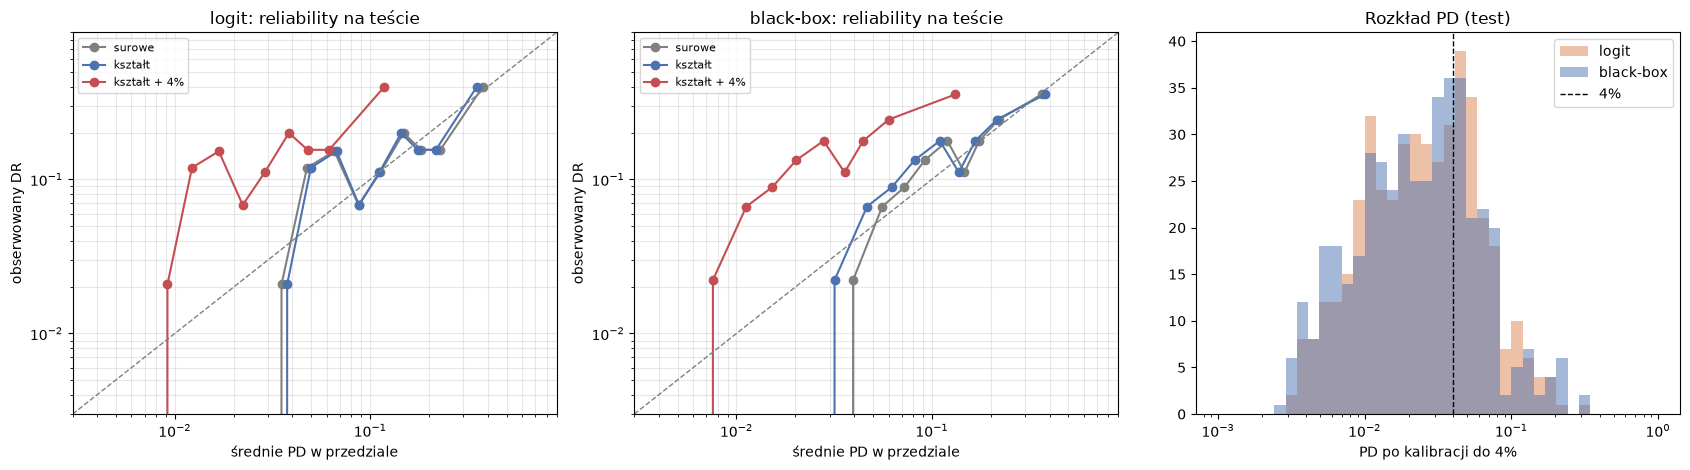

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

for ax, m in zip(axes, MODELS):
    for v, col in zip(Q[m], ['grey', '#4C72B0', '#C44E52']):
        reliability(ax, Y['test'], Q[m][v]['test'], v, color=col)
    log_axes(ax); ax.set_title(f'{m}: reliability na teście'); ax.legend(fontsize=8)
    
for m, col in zip(MODELS, ['#DD8452', '#4C72B0']):
    axes[2].hist(Q[m]['kształt + 4%']['test'], bins=np.logspace(-3, 0, 40), alpha=0.5, label=m, color=col)
    
axes[2].axvline(cfg.PD_TARGET, c='k', ls='--', lw=1, label='4%'); axes[2].set_xscale('log')
axes[2].set_xlabel('PD po kalibracji do 4%'); axes[2].set_title('Rozkład PD (test)'); axes[2].legend()

plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '06_post_cal_test.png', dpi=150); plt.show()

**Wnioski:**
- przed dostosowaniem (surowe, kształt) punkty leżą blisko przekątnej – modele są dobrze skalibrowane względem DR w danych (13,8%),
- po przesunięciu do 4% krzywa leży **powyżej** przekątnej: w każdym przedziale obserwowany DR jest wyższy od PD, średnio ok. 3,4 raza (CITL ≈ 1,55). Kształt krzywej jest zachowany, zmienia się tylko poziom – to zamierzony skutek założenia 4%, a nie błąd kształtu,
- rozkład PD po dostosowaniu (prawy wykres) jest skupiony wokół 1–5%, a ogon sięga ok. 30%. Oba modele mają bardzo podobny rozkład.

----
## 7. Zachowanie rankingu

In [8]:
rank = pd.DataFrame({m: {'AUC surowe': post.loc[(m, 'surowe'), 'AUC'], 'AUC po kalibracji': post.loc[(m, 'kształt + 4%'), 'AUC'],
                         'Spearman rang (surowe vs końcowe)': spearmanr(Q[m]['surowe']['test'], Q[m]['kształt + 4%']['test']).statistic,
                         'liczba różnych PD (test)': len(np.unique(Q[m]['kształt + 4%']['test']))} for m in MODELS}).T
rank.round(4)

,AUC surowe,AUC po kalibracji,Spearman rang (surowe vs końcowe),liczba różnych PD (test)
logit,0.7079,0.7079,1.0,390.0
black-box,0.7304,0.7304,1.0,448.0


**Wnioski:** Spearman = 1 i to samo AUC – kalibracja nie zmienia kolejności firm, więc nie zmienia zdolności modelu do szeregowania.

----
## 8. Wpływ na wyjaśnienia

In [9]:
for m in MODELS:
    method, cal = CAL[m]
    if method == 'Platt':
        print(f'{m}: Platt -> wszystkie φ × a = {cal.coef_[0][0]:.3f} (ranking przyczyn bez zmian), φ0 przesunięte o b + δ')
    else:
        print(f'{m}: izotoniczna -> wkłady SHAP modelu surowego NIE są wkładami modelu końcowego (wyjaśniamy model przed kalibracją)')

logit: Platt -> wszystkie φ × a = 0.935 (ranking przyczyn bez zmian), φ0 przesunięte o b + δ
black-box: Platt -> wszystkie φ × a = 1.105 (ranking przyczyn bez zmian), φ0 przesunięte o b + δ


**Wnioski:** Platt to przekształcenie liniowe w log-szansach, więc wkłady SHAP skalują się o a, a ranking przyczyn się nie zmienia.

----
## 9. Zapis wyników

In [10]:
rows = []
for m, key in MODELS.items():
    for s, ids in [('valid', va), ('test', te)]:
        rows.append(pd.DataFrame({'model': m, 'id': ids, 'zbior': s, 'p_surowe': Q[m]['surowe'][s],
                                  'p_ksztalt': Q[m]['kształt'][s], 'pd_4proc': Q[m]['kształt + 4%'][s]}))
pd.concat(rows).to_csv(cfg.ROOT / 'outputs/predictions/pd_skalibrowane.csv', index=False)
joblib.dump({m: {'metoda': CAL[m][0], 'kalibrator': CAL[m][1], 'delta': DELTA[m]} for m in MODELS},
            cfg.ROOT / 'outputs/models/kalibracja.joblib')

['C:\\Users\\barto\\Desktop\\XAI\\projekt_1_v2\\outputs\\models\\kalibracja.joblib']